# Session 6 demo, Part B: one predictor is rarely enough

A multiple regression on an **audit-fee** model. It reproduces the numbers on the Part B slides and runs in Colab with nothing to upload (the data is generated below so it matches the slides exactly).

The questions: what drives an audit fee, which drivers *earn their place*, and how one driver can look important until you control for client size.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# Generate the same 140-client panel as the slides (same seed and recipe).
rng = np.random.default_rng(6)
n = 140
assets = rng.gamma(2.0, 42, n)                       # total assets, EUR millions (client size)
locations = np.maximum(1, np.round(2 + 0.06 * assets + rng.normal(0, 1.2, n)))  # offices, a size proxy
subsidiaries = np.maximum(0, rng.poisson(4, n))      # complexity, unrelated to size
inventory_ratio = rng.uniform(10, 55, n)             # inventory + receivables, % of assets (risk)
listed = rng.binomial(1, 0.4, n)                     # 1 = listed, 0 = private
prior_issues = rng.poisson(2, n)                     # prior-year findings (noise)
fee = (25 + 0.9*assets + 3.0*subsidiaries + 0.8*inventory_ratio
       + 15.0*listed + rng.normal(0, 18, n))         # audit fee, EUR000s
af = pd.DataFrame(dict(fee=fee, assets=assets, locations=locations, subsidiaries=subsidiaries,
                       inventory_ratio=inventory_ratio, listed=listed, prior_issues=prior_issues))
af.round(1).head()

,fee,assets,locations,subsidiaries,inventory_ratio,listed,prior_issues
0,236.0,144.0,10.0,9,50.9,0,6
1,49.6,2.8,4.0,3,21.8,1,6
2,91.9,21.3,3.0,5,40.0,1,2
3,249.2,140.6,11.0,7,42.5,1,2
4,167.4,111.8,7.0,7,50.3,0,2


## 1. The coefficient that changes (the confounder)

**Predict first.** Big clients have many office locations *and* high audit fees. Do you think the number of locations really drives the fee, once you already know how big the client is? Write down your guess, then run the two models below.

In [2]:
# Locations on its own
m_loc = smf.ols('fee ~ locations', data=af).fit()
print('LOCATIONS ALONE')
print(f"  coefficient = {m_loc.params['locations']:.1f}k per location, p = {m_loc.pvalues['locations']:.2g}")

# Locations, with client size (assets) also in the model
m_both = smf.ols('fee ~ assets + locations', data=af).fit()
print('\nLOCATIONS, WITH CLIENT SIZE IN THE MODEL')
print(f"  locations = {m_both.params['locations']:.2f}k, p = {m_both.pvalues['locations']:.2f}")
print(f"  assets    = {m_both.params['assets']:.2f}k, p = {m_both.pvalues['assets']:.2g}")

LOCATIONS ALONE
  coefficient = 13.5k per location, p = 7.9e-43

LOCATIONS, WITH CLIENT SIZE IN THE MODEL
  locations = 1.40k, p = 0.35
  assets    = 0.80k, p = 1.2e-14


Locations looked like a strong, highly significant driver on its own. Once client size is in the model its effect **collapses toward zero and loses significance**: size was doing the work all along. Locations was a *confounder*, a stand-in for size. This is why you name each variable's role before you trust a coefficient.

## 2. The full model, and reading a dummy

`listed` is a category (listed or private), coded 0/1. Its coefficient reads as the **gap** between the two groups, holding the other drivers fixed.

In [3]:
full = smf.ols('fee ~ assets + subsidiaries + inventory_ratio + listed', data=af).fit()
print(full.summary())
print(f"\nListed clients cost about {full.params['listed']:.0f}k more to audit than comparable "
      f"private ones (the 'listed' coefficient), holding size, complexity and risk fixed.")

                            OLS Regression Results                            
Dep. Variable:                    fee   R-squared:                       0.895
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     288.2
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           4.72e-65
Time:                        17:39:16   Log-Likelihood:                -603.38
No. Observations:                 140   AIC:                             1217.
Df Residuals:                     135   BIC:                             1231.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          25.2582      6.171     

Read the table the same three ways as a simple regression: **model fit** (R-squared), the **overall F-test** (is the model better than no model?), and the **coefficients** (each with its own t and p). Every coefficient is 'the effect of this driver, holding the others fixed'.

## 3. R-squared always rises. Adjusted R-squared does not.

Add three columns of pure noise and watch what each score does.

In [4]:
af2 = af.copy()
for k in range(3):
    af2[f'noise{k}'] = rng.normal(0, 1, n)
junk = smf.ols('fee ~ assets + subsidiaries + inventory_ratio + listed + noise0 + noise1 + noise2',
               data=af2).fit()
print(f"Four real drivers:        R2 = {full.rsquared:.3f}   adjusted R2 = {full.rsquared_adj:.3f}")
print(f"+ three noise columns:    R2 = {junk.rsquared:.3f}   adjusted R2 = {junk.rsquared_adj:.3f}")
print('\nR-squared rose for nothing; adjusted R-squared saw through the noise.')

Four real drivers:        R2 = 0.895   adjusted R2 = 0.892
+ three noise columns:    R2 = 0.897   adjusted R2 = 0.891

R-squared rose for nothing; adjusted R-squared saw through the noise.


## 4. Which drivers earn their place (forward selection)

Add predictors one at a time, each time the one with the smallest p-value, and stop when the best remaining candidate no longer clears p < 0.05.

In [5]:
cands = ['assets', 'subsidiaries', 'inventory_ratio', 'listed', 'locations', 'prior_issues']
chosen = []
while cands:
    scored = [(c, smf.ols('fee ~ ' + ' + '.join(chosen + [c]), data=af).fit().pvalues[c]) for c in cands]
    best, best_p = min(scored, key=lambda t: t[1])
    if best_p >= 0.05:
        break
    chosen.append(best); cands.remove(best)
    print(f"add {best:16s} (p = {best_p:.2g})")
print('\nnever entered:', cands, '  <- the confounder and the noise')

add assets           (p = 1e-55)
add subsidiaries     (p = 6.7e-06)
add inventory_ratio  (p = 7.2e-06)
add listed           (p = 3.4e-06)

never entered: ['locations', 'prior_issues']   <- the confounder and the noise


## 5. When the line should bend (a non-linear taste)

Audit *effort* does not grow in a straight line with transaction volume: it saturates. A straight line underfits; transforming the predictor (here, log of volume) straightens it.

straight line: R2 = 0.79
bent (log):    R2 = 0.88


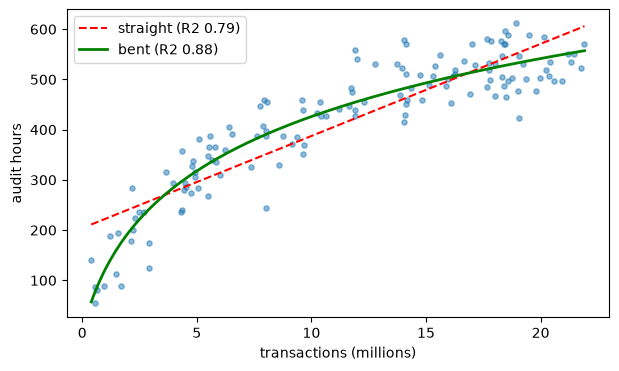

In [6]:
tx = np.sort(rng.uniform(0.3, 22, n))
hours = 180 * np.log(tx + 1) + rng.normal(0, 45, n)
d = pd.DataFrame({'tx': tx, 'hours': hours, 'log_tx': np.log(tx + 1)})
lin = smf.ols('hours ~ tx', data=d).fit()
log = smf.ols('hours ~ log_tx', data=d).fit()
print(f"straight line: R2 = {lin.rsquared:.2f}")
print(f"bent (log):    R2 = {log.rsquared:.2f}")

gx = np.linspace(tx.min(), tx.max(), 200)
plt.figure(figsize=(7, 4))
plt.scatter(tx, hours, s=14, alpha=0.5)
plt.plot(gx, lin.predict({'tx': gx}), 'r--', label=f'straight (R2 {lin.rsquared:.2f})')
plt.plot(gx, log.predict({'log_tx': np.log(gx + 1)}), 'g-', lw=2, label=f'bent (R2 {log.rsquared:.2f})')
plt.xlabel('transactions (millions)'); plt.ylabel('audit hours'); plt.legend(); plt.show()

### Takeaways

- A coefficient means *'holding the other drivers fixed'*, which is why a confounder (locations) can look important alone and vanish in context.
- Name each variable's role before you model: treatment, control, confounder, interaction.
- A dummy's coefficient is the gap between the groups.
- Compare models with **adjusted** R-squared, not R-squared.
- If the relationship bends, transform a predictor and fit a line to the new shape.